# Lab 01: Sentiment Analysis Using Traditional Machine Learning


The dataset contains 3,000 positive and negative sentences from IMDb, Amazon, and Yelp. Dataset: [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment%2Blabelled%2Bsentences). Please credit Kotzias et al. (2015), DOI: [10.24432/C57604](https://doi.org/10.24432/C57604).

Run the notebook from this `notebook` folder. The first code cell downloads the UCI ZIP when it is not already available locally.

In [1]:
from collections import Counter
from io import BytesIO
from pathlib import Path
import os
import re
import tempfile
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.tokenize import TreebankWordTokenizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
DATASET_URL = "https://archive.ics.uci.edu/static/public/331/sentiment%2Blabelled%2Bsentences.zip"
local_archive = Path("sentiment_labelled_sentences.zip")
configured_archive = os.environ.get("LAB01_DATASET_ZIP")

if configured_archive and Path(configured_archive).exists():
    archive_bytes = Path(configured_archive).read_bytes()
elif local_archive.exists():
    archive_bytes = local_archive.read_bytes()
else:
    with urllib.request.urlopen(DATASET_URL, timeout=60) as response:
        archive_bytes = response.read()

print(f"Loaded UCI dataset archive ({len(archive_bytes):,} bytes).")

Loaded UCI dataset archive (84,188 bytes).


## 1. Download and load the dataset

In [2]:
records = []
with zipfile.ZipFile(BytesIO(archive_bytes)) as archive:
    data_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith("_labelled.txt") and not name.startswith("__MACOSX/")
    )
    for name in data_files:
        source = Path(name).name.replace("_labelled.txt", "")
        pending = ""
        for line in archive.read(name).decode("utf-8", errors="replace").splitlines():
            if not line.strip():
                continue
            pending = f"{pending} {line.strip()}".strip()
            if re.search(r"\t[01]$", pending):
                sentence, label = pending.rsplit("\t", 1)
                records.append({"text": sentence, "label": int(label), "source": source})
                pending = ""
        if pending:
            raise ValueError(f"Could not parse final dataset row from {name}: {pending!r}")

df = pd.DataFrame(records)
df["sentiment"] = df["label"].map({0: "negative", 1: "positive"})
print(f"Rows: {len(df):,}; sources: {', '.join(data_files)}")
display(df.head())
display(df.groupby(["source", "sentiment"]).size().unstack(fill_value=0))
assert len(df) == 3000, f"Expected 3,000 rows, received {len(df)}"
assert df["label"].isin([0, 1]).all()

Rows: 3,000; sources: sentiment labelled sentences/amazon_cells_labelled.txt, sentiment labelled sentences/imdb_labelled.txt, sentiment labelled sentences/yelp_labelled.txt


,text,label,source,sentiment
0,So there is no way for me to plug it in here i...,0,amazon_cells,negative
1,"Good case, Excellent value.",1,amazon_cells,positive
2,Great for the jawbone.,1,amazon_cells,positive
3,Tied to charger for conversations lasting more...,0,amazon_cells,negative
4,The mic is great.,1,amazon_cells,positive


sentiment,negative,positive
source,,
amazon_cells,500,500
imdb,500,500
yelp,500,500


## 2. Preprocess the text and compare it with the original

In [3]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].map(clean_text)
display(df[["text", "clean_text", "sentiment"]].sample(10, random_state=RANDOM_STATE).reset_index(drop=True))

,text,clean_text,sentiment
0,Avoid at ALL costs!,avoid at all costs,negative
1,"Garbo, who showed right off the bat that her t...",garbo who showed right off the bat that her ta...,positive
2,You will leave the theater wanting to go out a...,you will leave the theater wanting to go out a...,positive
3,O my gosh the best phone I have ever had.,o my gosh the best phone i have ever had,positive
4,I would not recommend this place.,i would not recommend this place,negative
5,Then scene where they debated whether or not t...,then scene where they debated whether or not t...,negative
6,Her role was played well.,her role was played well,positive
7,"Nice, spicy and tender.",nice spicy and tender,positive
8,Plantronics Bluetooth Excelent Buy.,plantronics bluetooth excelent buy,positive
9,"As for the service: I'm a fan, because it's qu...",as for the service i m a fan because it s quic...,positive


## 3. Explore examples and frequently occurring words

In [4]:
print("Positive examples:")
display(df.loc[df.label == 1, ["text", "source"]].sample(5, random_state=RANDOM_STATE).reset_index(drop=True))
print("Negative examples:")
display(df.loc[df.label == 0, ["text", "source"]].sample(5, random_state=RANDOM_STATE).reset_index(drop=True))

# TreebankWordTokenizer works without downloading external NLTK corpora.
tokenizer = TreebankWordTokenizer()
stop_words = {
    "a", "an", "and", "are", "as", "at", "be", "been", "but", "by", "for", "from",
    "had", "has", "have", "he", "her", "his", "i", "if", "in", "is", "it", "its",
    "me", "my", "of", "on", "or", "our", "she", "so", "than", "that", "the", "their",
    "them", "there", "they", "this", "to", "was", "we", "were", "with", "you", "your", "s", "t"
}

def frequent_words(texts, limit=12):
    tokens = (token for text in texts for token in tokenizer.tokenize(text) if token not in stop_words and token.isalpha())
    return Counter(tokens).most_common(limit)

word_rows = []
for label, sentiment in [(1, "positive"), (0, "negative")]:
    for word, count in frequent_words(df.loc[df.label == label, "clean_text"]):
        word_rows.append({"sentiment": sentiment, "word": word, "count": count})
word_counts = pd.DataFrame(word_rows)
display(word_counts.pivot(index="word", columns="sentiment", values="count").fillna(0).astype(int))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False)
for ax, sentiment in zip(axes, ["positive", "negative"]):
    subset = word_counts[word_counts.sentiment == sentiment].sort_values("count")
    sns.barplot(data=subset, x="count", y="word", color=("#2a9d8f" if sentiment == "positive" else "#e76f51"), ax=ax)
    ax.set_title(f"Most frequent words: {sentiment}")
    ax.set_xlabel("Count")
    ax.set_ylabel("")
fig.tight_layout()
screenshots_dir = Path.cwd().parent / "screenshots"
screenshots_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(screenshots_dir / "lab01_word_frequencies.svg", bbox_inches="tight")
fig.savefig(screenshots_dir / "lab01_word_frequencies.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

Positive examples:
Negative examples:


,text,source
0,Very good lunch spot.,yelp
1,Both great!,yelp
2,Plan on ordering from them again and again.,amazon_cells
3,The reception through this headset is excellent.,amazon_cells
4,Best headset ever!!!.,amazon_cells


,text,source
0,I as well would've given godfathers zero stars...,yelp
1,Very poor service.,yelp
2,Just does not work.,amazon_cells
3,Terrible.. My car will not accept this cassette.,amazon_cells
4,While I managed to bend the leaf spring back i...,amazon_cells


sentiment,negative,positive
word,,
all,76,74
bad,100,0
best,0,63
don,64,0
film,0,105
food,66,60
good,0,177
great,0,201
just,66,0


<Figure size 1300x500 with 2 Axes>

## 4. Split the dataset

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.20, stratify=df["label"], random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts:", y_test.value_counts().sort_index().to_dict())

Training rows: 2,400; test rows: 600
Training class counts: {0: 1200, 1: 1200}
Test class counts: {0: 300, 1: 300}


## 5. Create BOW features; compare with TF-IDF

In [6]:
bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)
print(f"BOW matrix: {X_train_bow.shape[0]} training rows x {X_train_bow.shape[1]} learned features")

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print(f"TF-IDF matrix: {X_train_tfidf.shape[0]} training rows x {X_train_tfidf.shape[1]} learned features")

BOW matrix: 2400 training rows x 4506 learned features
TF-IDF matrix: 2400 training rows x 4506 learned features


## 6–7. Train Logistic Regression and evaluate performance

BOW model classification report:
              precision    recall  f1-score   support

    negative      0.827     0.813     0.820       300
    positive      0.816     0.830     0.823       300

    accuracy                          0.822       600
   macro avg      0.822     0.822     0.822       600
weighted avg      0.822     0.822     0.822       600



,Accuracy,Precision,Recall,F1
Model,,,,
BOW + Logistic Regression,0.822,0.816,0.830,0.823
TF-IDF + Logistic Regression,0.822,0.806,0.847,0.826


<Figure size 1300x500 with 2 Axes>

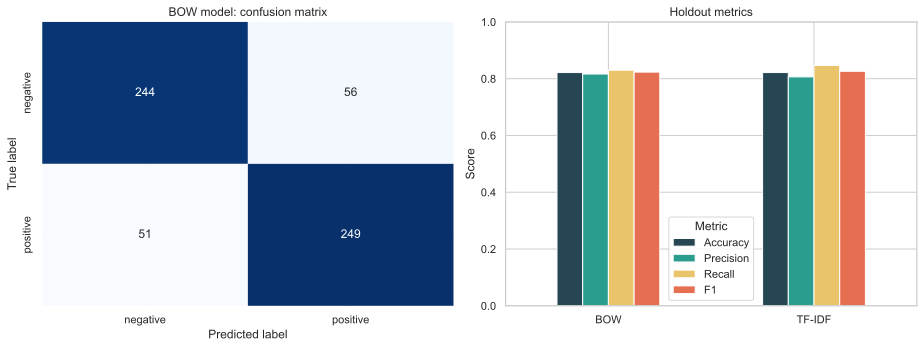

In [7]:
models = {
    "BOW + Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_train_bow, X_test_bow),
    "TF-IDF + Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_train_tfidf, X_test_tfidf),
}
results = []
predictions = {}
for name, (model, train_features, test_features) in models.items():
    model.fit(train_features, y_train)
    predicted = model.predict(test_features)
    predictions[name] = predicted
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))
print("BOW model classification report:")
print(classification_report(y_test, predictions["BOW + Logistic Regression"], target_names=["negative", "positive"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_test, predictions["BOW + Logistic Regression"]), annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["negative", "positive"], yticklabels=["negative", "positive"], ax=axes[0])
axes[0].set(title="BOW model: confusion matrix", xlabel="Predicted label", ylabel="True label")
results_df.plot(kind="bar", ylim=(0, 1), ax=axes[1], color=["#264653", "#2a9d8f", "#e9c46a", "#e76f51"])
axes[1].set(title="Holdout metrics", ylabel="Score", xlabel="", xticklabels=["BOW", "TF-IDF"])
axes[1].legend(title="Metric")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
screenshots_dir = Path.cwd().parent / "screenshots"
screenshots_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(screenshots_dir / "lab01_model_evaluation.svg", bbox_inches="tight")
fig.savefig(screenshots_dir / "lab01_model_evaluation.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 8. Test the model with a new sentence

In [8]:
new_sentence = "This product exceeded my expectations and I would gladly recommend it."
new_clean = clean_text(new_sentence)
new_prediction = models["BOW + Logistic Regression"][0].predict(bow.transform([new_clean]))[0]
new_probabilities = models["BOW + Logistic Regression"][0].predict_proba(bow.transform([new_clean]))[0]
print(f"Sentence: {new_sentence}")
print(f"Predicted sentiment: {'positive' if new_prediction == 1 else 'negative'}")
print(f"Class probabilities (negative, positive): {np.round(new_probabilities, 3)}")

Sentence: This product exceeded my expectations and I would gladly recommend it.
Predicted sentiment: positive
Class probabilities (negative, positive): [0.28 0.72]


## Observations and learning outcomes

Use the outputs above to compare the original and cleaned text, inspect frequent words in each sentiment class, and compare BOW with TF-IDF on the same stratified holdout split. The measured scores are specific to this dataset split and are not a guarantee of performance on other review sources. The model predicts sentiment from word features; it does not understand context, sarcasm, or domain changes.